In [2]:
import os, sys, shutil, random
import numpy as np, pandas as pd
from pathlib import Path

SEED = 0
random.seed(SEED); np.random.seed(SEED)

SRC = Path("/kaggle/input/datasets/ponishbhatia/cs771-data")   # <-- edit

WORK = Path("/kaggle/working"); (WORK / "data").mkdir(exist_ok=True)
for f in ["bihar_pm25_hourly_jan_nov_2024.csv", "bihar_stations.csv"]:
    shutil.copy(next(SRC.rglob(f)), WORK / "data" / f)
shutil.copy(next(SRC.rglob("baseline*.py")), WORK / "baseline.py")
sys.path.insert(0, str(WORK)); os.chdir(WORK)

import baseline as B
B.self_check()      # must print "baseline.py OK" (reproduces 32.75 / 29.58 + leakage test)

baseline.py OK


,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81


In [3]:
W, stations = B.load_data()
T_tr, T_va = B.issue_times()
y_tr, y_va = B.targets(W, T_tr), B.targets(W, T_va)
A = B.neighbour_matrix(stations)
X_tr, X_va = B.part1_features(W, T_tr, A), B.part1_features(W, T_va, A)

print(X_tr.shape, X_va.shape)                    # (113256, 29) (42588, 29)
assert len(y_tr) == 113_256 and len(y_va) == 42_588
assert T_tr.max() + pd.Timedelta(hours=24) <= pd.Timestamp("2024-08-31 12:00")   # last train target <= 31 Aug
assert T_va.min() + pd.Timedelta(hours=24) >= pd.Timestamp("2024-09-01 12:00")   # first val target >= 1 Sep

# reproduce Part 1 ridge
from sklearn.linear_model import Ridge
p1 = Ridge(alpha=1.0).fit(X_tr, y_tr).predict(X_va)
print(B.evaluate(p1, y_va, T_va))                # RMSE should be 29.58, MAE 18.16

# check our y aligns with the team's file (if uploaded)
# bp = pd.read_csv(SRC/"baseline_predictions.csv"); print(np.allclose(bp[bp.split=="val"].y_true.values, y_va))

(113256, 29) (42588, 29)
{'RMSE': np.float64(29.584138830945392), 'MAE': np.float64(18.15595707645632), 'RMSE Sep': np.float64(20.337770578277496), 'MAE Sep': np.float64(10.348094860161021), 'RMSE Oct': np.float64(19.360076491644293), 'MAE Oct': np.float64(13.463569383929267), 'RMSE Nov': np.float64(43.057016008263545), 'MAE Nov': np.float64(30.81261990836291)}


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def rmse(p, y): return np.sqrt(np.mean((np.clip(p, 0, None) - y) ** 2))

rows = []
for a in np.logspace(-2, 7, 19):                  # wide grid: shrinkage only bites at large alpha with n~1e5
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_tr, y_tr)   # scaler fit on train only
    pt, pv = m.predict(X_tr), m.predict(X_va)
    ev = B.evaluate(pv, y_va, T_va)
    rows.append(dict(alpha=a, train_rmse=rmse(pt, y_tr), val_rmse=ev["RMSE"], val_mae=ev["MAE"],
                     rmse_sep=ev["RMSE Sep"], rmse_oct=ev["RMSE Oct"], rmse_nov=ev["RMSE Nov"],
                     val_bias=np.mean(np.clip(pv, 0, None) - y_va)))
sweep_level = pd.DataFrame(rows)
print(sweep_level.round(3).to_string(index=False))

       alpha  train_rmse  val_rmse  val_mae  rmse_sep  rmse_oct  rmse_nov  val_bias
       0.010      27.998    29.584   18.156    20.338    19.360    43.057     5.318
       0.032      27.998    29.584   18.156    20.338    19.360    43.057     5.318
       0.100      27.998    29.584   18.156    20.338    19.360    43.057     5.318
       0.316      27.998    29.584   18.156    20.338    19.360    43.057     5.318
       1.000      27.998    29.584   18.156    20.338    19.361    43.057     5.319
       3.162      27.998    29.585   18.157    20.338    19.361    43.057     5.320
      10.000      27.998    29.585   18.159    20.339    19.364    43.057     5.325
      31.623      27.998    29.588   18.164    20.342    19.372    43.057     5.341
     100.000      27.998    29.595   18.181    20.349    19.396    43.058     5.390
     316.228      28.000    29.620   18.233    20.373    19.471    43.064     5.533
    1000.000      28.011    29.700   18.379    20.436    19.679    43.102   

The alpha sweep is a null result for the level target. Val RMSE is flat at 29.584 up to α≈10 and then rises monotonically. There’s no interior optimum, so standardised ridge is effectively OLS here, and 113k rows against 29 features leaves nothing for the penalty to fix. This is worth a sentence in the report, but it means gains won’t come from regularisation.

The train/val gap is small (28.0 vs 29.6), so this isn’t overfitting. The real problem is the +5.3 val bias from distribution shift. It only crosses zero around α≈1e6, where the model has degraded to the training mean (RMSE 33.6). So the next suspects are the sin/cos columns and the intercept, which encode Jan–Aug seasonality that doesn’t carry over to Sep–Nov. That makes the target comparison and the no-sin/cos test the most informative next steps.


In [5]:
import warnings; warnings.filterwarnings("ignore")
lag0_tr, lag0_va = X_tr[:, 0], X_va[:, 0]          # y(t), already in the 29 features (col 0)
months_va = np.repeat((T_va + pd.Timedelta(hours=24)).month, 468)
LOG = []

def log_run(model, features, target, hp, p_tr, p_va, notes="", save_as=None):
    ev = B.evaluate(p_va, y_va, T_va)
    row = dict(Member="B", Model=model, Features=features, Target=target, Hyperparameters=hp,
               Train_RMSE=rmse(p_tr, y_tr), Val_RMSE=ev["RMSE"], Val_MAE=ev["MAE"],
               Sep=ev["RMSE Sep"], Oct=ev["RMSE Oct"], Nov=ev["RMSE Nov"],
               Bias=np.mean(np.clip(p_va, 0, None) - y_va), Notes=notes)
    LOG.append(row)
    if save_as:                                     # 91 x 468 val preds for Part 4
        os.makedirs("preds", exist_ok=True)
        df = pd.DataFrame(np.clip(p_va, 0, None).reshape(len(T_va), 468),
                          index=T_va + pd.Timedelta(hours=24), columns=stations.index)
        df.to_parquet(f"preds/{save_as}.parquet")
    return row

def fit_targets(Xtr, Xva, alpha):
    """One standardised-ridge fit per target; everything converted back to ug/m3.
    Scaler + smearing factor are fit on TRAIN rows only."""
    out = {}
    def fit(z):
        m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xtr, z)
        return m.predict(Xtr), m.predict(Xva)
    a, b = fit(y_tr);                 out["level"]  = (a, b)
    a, b = fit(y_tr - lag0_tr);       out["change"] = (a + lag0_tr, b + lag0_va)
    z = np.log1p(y_tr)
    a, b = fit(z)
    clipz = lambda v: np.clip(v, 0, 7)
    out["log"] = (np.expm1(clipz(a)), np.expm1(clipz(b)))
    S = np.mean(np.exp(z - a))                       # Duan smearing, train residuals only
    out["log_smear"] = (np.exp(clipz(a)) * S - 1, np.exp(clipz(b)) * S - 1)
    return out

rows = []
for al in np.logspace(-2, 8, 11):
    for tgt, (pt, pv) in fit_targets(X_tr, X_va, al).items():
        r = log_run("ridge-std", "part1_29", tgt, f"alpha={al:g}", pt, pv)
        rows.append({**r, "alpha": al})
cmp_t = pd.DataFrame(rows)
cols = ["alpha", "Target", "Train_RMSE", "Val_RMSE", "Val_MAE", "Sep", "Oct", "Nov", "Bias"]
print(cmp_t[cols].round(2).to_string(index=False))

       alpha    Target  Train_RMSE  Val_RMSE  Val_MAE   Sep   Oct    Nov   Bias
        0.01     level       28.00     29.58    18.16 20.34 19.36  43.06   5.32
        0.01    change       28.00     29.58    18.16 20.34 19.36  43.06   5.32
        0.01       log       42.97     40.86    23.22 20.68 24.61  63.32 -14.81
        0.01 log_smear       52.17     41.36    21.41 20.13 21.93  65.47  -7.40
        0.10     level       28.00     29.58    18.16 20.34 19.36  43.06   5.32
        0.10    change       28.00     29.58    18.16 20.34 19.36  43.06   5.32
        0.10       log       42.97     40.86    23.22 20.68 24.61  63.32 -14.81
        0.10 log_smear       52.17     41.36    21.41 20.13 21.93  65.47  -7.40
        1.00     level       28.00     29.58    18.16 20.34 19.36  43.06   5.32
        1.00    change       28.00     29.58    18.16 20.34 19.36  43.06   5.32
        1.00       log       42.97     40.86    23.22 20.68 24.61  63.32 -14.81
        1.00 log_smear       52.17     4

In [6]:
keep = list(range(27))                              # drop cols 27, 28 = sin_doy, cos_doy
Xtr_nc, Xva_nc = X_tr[:, keep], X_va[:, keep]
for al in [1.0, 1e3, 1e5]:
    for tgt, (pt, pv) in fit_targets(Xtr_nc, Xva_nc, al).items():
        log_run("ridge-std", "part1_29 minus sin/cos", tgt, f"alpha={al:g}", pt, pv)
nc = pd.DataFrame(LOG[-12:])
print(nc[["Features", "Target", "Hyperparameters", "Train_RMSE", "Val_RMSE", "Val_MAE", "Sep", "Oct", "Nov", "Bias"]].round(2).to_string(index=False))

# monthly mean error for level target, with vs without sin/cos (alpha=1)
pv_full = fit_targets(X_tr, X_va, 1.0)["level"][1]
pv_nc   = fit_targets(Xtr_nc, Xva_nc, 1.0)["level"][1]
for nm, pv in [("with sin/cos", pv_full), ("no sin/cos", pv_nc)]:
    e = np.clip(pv, 0, None) - y_va
    print(nm, {m: round(e[months_va == m].mean(), 2) for m in (9, 10, 11)})

              Features    Target Hyperparameters  Train_RMSE  Val_RMSE  Val_MAE   Sep   Oct   Nov   Bias
part1_29 minus sin/cos     level         alpha=1       28.06     29.16    16.69 19.61 18.20 43.04  -0.50
part1_29 minus sin/cos    change         alpha=1       28.06     29.16    16.69 19.61 18.20 43.04  -0.50
part1_29 minus sin/cos       log         alpha=1       48.50     43.40    23.27 20.55 24.26 68.43 -10.77
part1_29 minus sin/cos log_smear         alpha=1       60.14     47.95    22.82 20.11 21.65 78.02  -2.23
part1_29 minus sin/cos     level      alpha=1000       28.07     29.15    16.72 19.63 18.28 42.98  -0.28
part1_29 minus sin/cos    change      alpha=1000       28.11     29.07    16.64 19.61 18.19 42.85  -0.31
part1_29 minus sin/cos       log      alpha=1000       48.36     43.42    23.29 20.64 24.24 68.46 -10.55
part1_29 minus sin/cos log_smear      alpha=1000       59.92     48.15    22.90 20.19 21.63 78.37  -1.97
part1_29 minus sin/cos     level    alpha=100000       

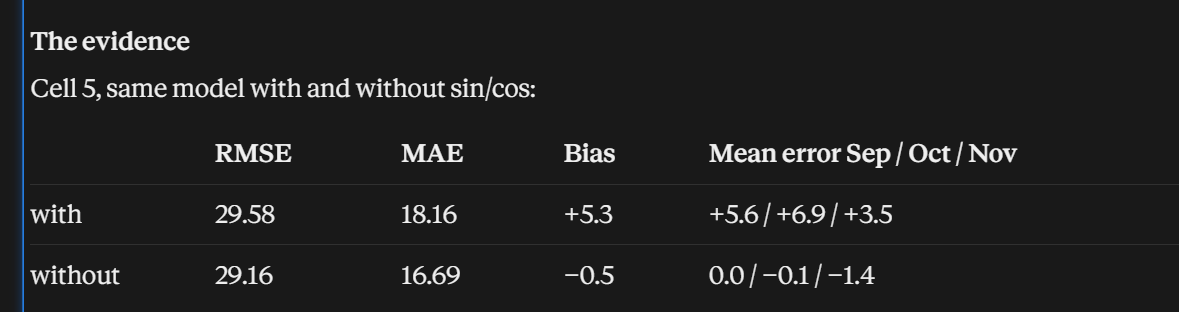

In [7]:
%%writefile features_B.py
import numpy as np, pandas as pd
import baseline as B
N = 468

def _i(W, T):
    i = W.index.get_indexer(pd.DatetimeIndex(T)); assert (i >= 0).all(); return i
def _cs(W):
    return np.vstack([np.zeros((1, W.shape[1])), np.cumsum(W.to_numpy(), axis=0)])
def _wmean(cs, i, H):                      # mean over hours i-H+1..i, window clipped at data start
    lo = np.maximum(0, i - H + 1); return (cs[i + 1] - cs[lo]) / (i + 1 - lo)[:, None]
def _rep(a): return np.repeat(a, N, axis=0)

def build_ctx(W, stations, train_end="2024-08-31 12:00"):
    xy = stations[["x_km", "y_km"]].to_numpy()
    D = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(2)); np.fill_diagonal(D, np.inf)
    R = []
    for r in (10, 25, 50):
        M = (D <= r).astype(float); e = M.sum(1) == 0
        M[e, D[e].argmin(1)] = 1.0; R.append(M / M.sum(1, keepdims=True))
    return dict(A10=B.neighbour_matrix(stations), R=R, st_mean=W.loc[:train_end].mean().to_numpy())

def own(W, T, ctx):
    L = B.lag_stack(W, T, 24); return L.reshape(-1, 24), [f"lag{k}" for k in range(24)]

def prevday(W, T, ctx):
    Wv, i = W.to_numpy(), _i(W, T); assert (i - 168 >= 0).all()
    X = np.stack([Wv[i - 24 * k] for k in range(1, 8)], axis=2)
    return X.reshape(-1, 7), [f"d{k}" for k in range(1, 8)]

def trend(W, T, ctx):
    cs, i = _cs(W), _i(W, T)
    cur = _wmean(cs, i, 24)                              # mean of hours i-23..i
    lo, hi = np.maximum(0, i - 47), i - 24               # previous 24 h window, clipped at data start
    prev = (cs[hi + 1] - cs[lo]) / (hi + 1 - lo)[:, None]
    return (cur - prev).reshape(-1, 1), ["trend24"]

def long(W, T, ctx):
    cs, i = _cs(W), _i(W, T)
    X = np.stack([_wmean(cs, i, 168), _wmean(cs, i, 720), np.tile(ctx["st_mean"], (len(i), 1))], axis=2)
    return X.reshape(-1, 3), ["mean7d", "mean30d", "train_mean"]

def nbr(W, T, ctx):
    cs, i = _cs(W), _i(W, T); Wv = W.to_numpy()
    cols = [Wv[i] @ ctx["A10"].T, _wmean(cs, i, 24) @ ctx["A10"].T] + [Wv[i] @ M.T for M in ctx["R"]]
    return np.stack(cols, axis=2).reshape(-1, 5), ["nbr10_now", "nbr10_mean24", "nbr_r10", "nbr_r25", "nbr_r50"]

def network(W, T, ctx):
    Wv, i = W.to_numpy(), _i(W, T)
    now = Wv[i].mean(1); chg = now - Wv[i - 24].mean(1); sd = Wv[i].std(1)
    return _rep(np.column_stack([now, chg, sd])), ["net_now", "net_chg24", "net_std"]

def calendar(W, T, ctx):
    dow = (pd.DatetimeIndex(T) + pd.Timedelta(hours=24)).dayofweek.to_numpy()   # day of the TARGET
    return _rep(np.eye(7)[dow][:, 1:]), [f"dow{k}" for k in range(1, 7)]

def transform(W, T, ctx):
    Wv, i = W.to_numpy(), _i(W, T)
    cols = [np.log1p(Wv[i]), np.log1p(Wv[i] @ ctx["A10"].T), np.log1p(np.repeat(Wv[i].mean(1)[:, None], N, 1))]
    return np.stack(cols, axis=2).reshape(-1, 3), ["log_lag0", "log_nbr10", "log_net"]

GROUPS = dict(own=own, prevday=prevday, trend=trend, long=long, nbr=nbr, network=network, calendar=calendar, transform=transform)

Overwriting features_B.py


In [8]:
import importlib, features_B as F; importlib.reload(F)
ctx = F.build_ctx(W, stations)

mask_T = T_tr >= pd.Timestamp("2024-01-08 12:00")        # 7 days of history for every group
T_trm = T_tr[mask_T]; rm = np.repeat(mask_T, 468)
y_trm, lag0_trm = y_tr[rm], X_tr[rm, 0]
print("train rows:", len(y_trm), "| val rows:", len(y_va))

blk_tr = {g: f(W, T_trm, ctx) for g, f in F.GROUPS.items()}
blk_va = {g: f(W, T_va, ctx) for g, f in F.GROUPS.items()}

# leakage + parity tests
for g, f in F.GROUPS.items():
    for T_, blk, j in [(T_va, blk_va, 10), (T_trm, blk_tr, 5)]:
        t = T_[j]
        a = f(W, [t], ctx)[0]; b = f(W.loc[:t], [t], ctx)[0]
        assert np.allclose(a, b), f"LEAK in {g}"
        assert np.allclose(a, blk[g][0][j * 468:(j + 1) * 468]), f"PARITY in {g}"
print("leakage + parity OK:", {g: blk_tr[g][0].shape[1] for g in blk_tr})

def run_groups(groups, alpha=1.0, target="level", save_as=None):
    Xa = np.hstack([blk_tr[g][0] for g in groups]); Xb = np.hstack([blk_va[g][0] for g in groups])
    off_tr, off_va = (lag0_trm, X_va[:, 0]) if target == "change" else (0, 0)
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xa, y_trm - off_tr)   # scaler: train rows only
    pt, pv = m.predict(Xa) + off_tr, m.predict(Xb) + off_va
    ev = B.evaluate(pv, y_va, T_va)
    row = dict(groups="+".join(groups), n_feat=Xa.shape[1], train_rmse=rmse(pt, y_trm), val_rmse=ev["RMSE"],
               val_mae=ev["MAE"], sep=ev["RMSE Sep"], oct=ev["RMSE Oct"], nov=ev["RMSE Nov"],
               bias=np.mean(np.clip(pv, 0, None) - y_va))
    if save_as:
        os.makedirs("preds", exist_ok=True)
        pd.DataFrame(np.clip(pv, 0, None).reshape(len(T_va), 468), index=T_va + pd.Timedelta(hours=24),
                     columns=stations.index).to_parquet(f"preds/{save_as}.parquet")
    return row

res = [run_groups(["own"])]
for g in [g for g in F.GROUPS if g != "own"]:
    res.append(run_groups(["own", g]))
res.append(run_groups(list(F.GROUPS), save_as="B_ridge_allgroups_level"))
tab = pd.DataFrame(res); tab["d_val_rmse"] = tab.val_rmse - tab.val_rmse.iloc[0]
print(tab.round(2).to_string(index=False))

train rows: 110448 | val rows: 42588
leakage + parity OK: {'own': 24, 'prevday': 7, 'trend': 1, 'long': 3, 'nbr': 5, 'network': 3, 'calendar': 6, 'transform': 3}
                                               groups  n_feat  train_rmse  val_rmse  val_mae   sep   oct   nov  bias  d_val_rmse
                                                  own      24       27.79     29.86    17.29 19.69 19.30 43.96  0.58        0.00
                                          own+prevday      31       27.22     29.89    17.16 19.47 18.88 44.29 -1.17        0.02
                                            own+trend      25       27.72     29.82    17.30 19.62 19.36 43.88  0.55       -0.04
                                             own+long      27       27.47     29.81    16.97 19.57 18.59 44.22 -3.84       -0.05
                                              own+nbr      29       27.50     29.44    16.96 19.71 18.57 43.41 -0.20       -0.42
                                          own+network      27   

What I’m looking for
(a): removing long (and maybe prevday or trend) from the full model should recover a lot of the 30.31. That confirms the mean-reversion story. Removing network should hurt most.
(b): if mean30d or mean7d carries a strongly negative bias and the others don’t, that’s direct evidence. Check whether net_chg24 or net_std is the useful part of network.
(c): the selected set, and whether a larger α now helps. With correlated groups it might, unlike with the 29 base features.

In [9]:
feat_tr = {n: blk_tr[g][0][:, j] for g in blk_tr for j, n in enumerate(blk_tr[g][1])}
feat_va = {n: blk_va[g][0][:, j] for g in blk_va for j, n in enumerate(blk_va[g][1])}

def run_feats(names, alpha=1.0, target="level", save_as=None):
    Xa = np.column_stack([feat_tr[n] for n in names]); Xb = np.column_stack([feat_va[n] for n in names])
    off_tr, off_va = (lag0_trm, X_va[:, 0]) if target == "change" else (0, 0)
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xa, y_trm - off_tr)
    pt, pv = m.predict(Xa) + off_tr, m.predict(Xb) + off_va
    ev = B.evaluate(pv, y_va, T_va)
    if save_as:
        os.makedirs("preds", exist_ok=True)
        pd.DataFrame(np.clip(pv, 0, None).reshape(len(T_va), 468), index=T_va + pd.Timedelta(hours=24),
                     columns=stations.index).to_parquet(f"preds/{save_as}.parquet")
    return dict(n_feat=Xa.shape[1], train=rmse(pt, y_trm), val=ev["RMSE"], mae=ev["MAE"],
                sep=ev["RMSE Sep"], oct=ev["RMSE Oct"], nov=ev["RMSE Nov"], bias=np.mean(np.clip(pv, 0, None) - y_va))

gnames = lambda gs: [n for g in gs for n in blk_tr[g][1]]
ALL = list(F.GROUPS)

# (a) drop-one-group from ALL (this is the ablation table for the all-groups model)
full = run_feats(gnames(ALL))
rows = [dict(removed="(none)", **full, d_val=0.0)]
for g in ALL:
    r = run_feats(gnames([x for x in ALL if x != g])); rows.append(dict(removed=g, **r, d_val=r["val"] - full["val"]))
print(pd.DataFrame(rows).round(2).to_string(index=False))

# (b) single features from long/network/trend on top of own+nbr: who causes the negative bias?
base = gnames(["own", "nbr"])
rows = []
for n in feat_tr:
    if n in base or n.startswith(("lag", "dow", "log_")): continue
    rows.append(dict(add=n, **run_feats(base + [n])))
print(pd.DataFrame(rows).round(2).to_string(index=False))

# (c) greedy forward selection over groups (selection on val: note optimism in the report)
sel, best = ["own"], run_feats(gnames(["own"]))["val"]
while True:
    cand = [(run_feats(gnames(sel + [g]))["val"], g) for g in ALL if g not in sel]
    if not cand: break
    v, g = min(cand)
    if best - v < 0.05: break
    sel.append(g); best = v; print("add", g, round(v, 3))
print("selected:", sel)
print(pd.DataFrame([run_feats(gnames(sel), alpha=a) | {"alpha": a} for a in [1, 100, 1e3, 1e4]]).round(2).to_string(index=False))

  removed  n_feat  train   val   mae   sep   oct   nov  bias  d_val
   (none)      52  26.25 30.31 17.03 19.59 18.32 45.34 -7.38   0.00
      own      28  26.98 32.04 18.06 20.48 19.41 48.01 -8.61   1.73
  prevday      45  26.54 29.70 16.73 19.66 18.38 44.05 -6.71  -0.61
    trend      51  26.26 30.35 17.04 19.60 18.33 45.41 -7.39   0.04
     long      49  26.42 29.07 16.32 19.42 17.84 43.09 -2.94  -1.24
      nbr      47  26.32 30.20 17.01 19.66 18.36 45.07 -6.88  -0.11
  network      49  26.66 30.58 17.37 19.72 18.39 45.81 -6.28   0.27
 calendar      46  26.31 30.27 17.04 19.56 18.38 45.24 -7.31  -0.04
transform      49  26.30 29.96 16.78 19.66 17.81 44.81 -6.14  -0.35
       add  n_feat  train   val   mae   sep   oct   nov  bias
        d1      30  27.48 29.48 16.97 19.67 18.56 43.52 -0.29
        d2      30  27.10 29.76 17.13 19.66 18.65 44.06 -0.80
        d3      30  27.29 29.49 16.94 19.56 18.46 43.62 -0.94
        d4      30  27.34 29.44 16.83 19.58 18.41 43.53 -1.04
        d5

In [10]:
from sklearn.linear_model import Lasso
SEL = ["own", "network", "trend", "nbr"]

# full train rows for the selected groups + leakage/parity tests
blk_tr_f = {g: F.GROUPS[g](W, T_tr, ctx) for g in SEL}
for g in SEL:
    for T_, blk, j in [(T_tr, blk_tr_f, 0), (T_tr, blk_tr_f, 100), (T_va, blk_va, 10)]:
        t = T_[j]; a = F.GROUPS[g](W, [t], ctx)[0]
        assert np.allclose(a, F.GROUPS[g](W.loc[:t], [t], ctx)[0]), f"LEAK {g}"
        assert np.allclose(a, blk[g][0][j*468:(j+1)*468]), f"PARITY {g}"
print("OK | train rows:", len(y_tr), "| val rows:", len(y_va))

def fit_eval(groups, alpha=100, target="level", save_as=None, tag=None):
    Xa = np.hstack([blk_tr_f[g][0] for g in groups]); Xb = np.hstack([blk_va[g][0] for g in groups])
    otr, ova = (X_tr[:, 0], X_va[:, 0]) if target == "change" else (0, 0)
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xa, y_tr - otr)   # scaler on train only
    pt, pv = m.predict(Xa) + otr, m.predict(Xb) + ova
    if tag: log_run("ridge-std", tag, target, f"alpha={alpha:g}", pt, pv, save_as=save_as)
    ev = B.evaluate(pv, y_va, T_va)
    return dict(n_feat=Xa.shape[1], train=rmse(pt, y_tr), val=ev["RMSE"], mae=ev["MAE"], sep=ev["RMSE Sep"],
                oct=ev["RMSE Oct"], nov=ev["RMSE Nov"], bias=np.mean(np.clip(pv, 0, None) - y_va)), m, pv

# 1. final model, level vs change across alpha
rows = []
for tgt in ["level", "change"]:
    for a in [1, 100, 1e3, 1e4]:
        r, _, _ = fit_eval(SEL, a, tgt); rows.append(dict(target=tgt, alpha=a, **r))
print(pd.DataFrame(rows).round(2).to_string(index=False))

# 2. ablation from the FINAL model (same alpha, same train rows)
full, m_full, pv_full = fit_eval(SEL, 100, "level", save_as="B_ridge_final_level", tag="own+network+trend+nbr")
rows = [dict(removed="(none)", n_removed=0, **full, d_val=0.0)]
for g in SEL:
    r, _, _ = fit_eval([x for x in SEL if x != g], 100)
    rows.append(dict(removed=g, n_removed=blk_tr_f[g][0].shape[1], **r, d_val=r["val"] - full["val"]))
print(pd.DataFrame(rows).round(2).to_string(index=False))

# 3. standardised coefficients (ug/m3 per 1 sd), top 12
names = [n for g in SEL for n in blk_tr_f[g][1]]
coef = pd.Series(m_full[-1].coef_, index=names); print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(2))

# 4. lasso path on ALL 52 features (rows from 8 Jan, same as the group-add table) -> which groups survive
Xa = np.hstack([blk_tr[g][0] for g in ALL]); Xb = np.hstack([blk_va[g][0] for g in ALL]); nm = gnames(ALL)
grp_of = [g for g in ALL for _ in blk_tr[g][1]]
sc = StandardScaler().fit(Xa); Za, Zb = sc.transform(Xa), sc.transform(Xb)
rows = []
for a in np.logspace(-2, 1.5, 8):
    ls = Lasso(alpha=a, max_iter=20000, random_state=0).fit(Za, y_trm)
    pv = ls.predict(Zb); nz = ls.coef_ != 0
    ev = B.evaluate(pv, y_va, T_va)
    rows.append(dict(alpha=round(a, 3), nnz=int(nz.sum()), val=ev["RMSE"], mae=ev["MAE"],
                     bias=np.mean(np.clip(pv, 0, None) - y_va), **{g: int(sum(nz[i] for i, gg in enumerate(grp_of) if gg == g)) for g in ALL}))
print(pd.DataFrame(rows).round(2).to_string(index=False))
ls = Lasso(alpha=1.0, max_iter=20000, random_state=0).fit(Za, y_trm)
print("lasso a=1, nonzero:", [n for n, c in zip(nm, ls.coef_) if c != 0])

# 5. final comparison table
print(B.compare({"B ridge final (own+network+trend+nbr)": pv_full}, W, stations, T_va))

OK | train rows: 113256 | val rows: 42588
target   alpha  n_feat  train   val   mae   sep   oct   nov  bias
 level     1.0      33  27.87 28.71 16.43 19.51 18.16 42.18 -0.53
 level   100.0      33  27.87 28.71 16.43 19.51 18.16 42.17 -0.48
 level  1000.0      33  27.89 28.73 16.48 19.55 18.23 42.16 -0.15
 level 10000.0      33  28.11 29.08 16.87 19.78 18.60 42.61  0.75
change     1.0      33  27.87 28.71 16.43 19.51 18.15 42.17 -0.53
change   100.0      33  27.87 28.69 16.42 19.51 18.15 42.15 -0.48
change  1000.0      33  27.93 28.65 16.42 19.52 18.15 42.05 -0.19
change 10000.0      33  28.90 29.21 16.53 20.40 18.53 42.63  0.14
removed  n_removed  n_feat  train   val   mae   sep   oct   nov  bias  d_val
 (none)          0      33  27.87 28.71 16.43 19.51 18.16 42.17 -0.48   0.00
    own         24       9  33.87 36.34 21.10 23.18 21.77 54.58 -1.33   7.63
network          3      30  28.43 29.35 16.94 19.64 18.65 43.21  0.08   0.64
  trend          1      32  27.97 28.88 16.49 19.58 18.1

In [11]:
rng = np.random.default_rng(0)
day_se = lambda pv: ((np.clip(pv, 0, None) - y_va) ** 2).reshape(len(T_va), 468).mean(1)

def block_boot(se_a, se_b, block=7, nb=2000):
    n = len(se_a); nblk = int(np.ceil(n / block)); out = []
    for _ in range(nb):
        s = rng.integers(0, n - block + 1, nblk)
        idx = np.concatenate([np.arange(a, a + block) for a in s])[:n]
        out.append(np.sqrt(se_a[idx].mean()) - np.sqrt(se_b[idx].mean()))
    return np.percentile(out, [2.5, 50, 97.5]).round(2)

se_final = day_se(pv_full)
cands = {"Ridge Part 1": day_se(p1),
         "Persistence": day_se(B.persistence(W, T_va)),
         "final minus network": day_se(fit_eval([g for g in SEL if g != "network"], 100)[2]),
         "final minus trend":   day_se(fit_eval([g for g in SEL if g != "trend"], 100)[2]),
         "final minus nbr":     day_se(fit_eval([g for g in SEL if g != "nbr"], 100)[2])}
print("delta RMSE = RMSE(final) - RMSE(other), 95% block-bootstrap CI [2.5, 50, 97.5]")
for k, se in cands.items(): print(f"{k:22s}", block_boot(se_final, se))

pd.DataFrame(LOG).to_csv("results_log_B.csv", index=False)
print(os.listdir("preds"))

delta RMSE = RMSE(final) - RMSE(other), 95% block-bootstrap CI [2.5, 50, 97.5]
Ridge Part 1           [-1.2  -0.62 -0.18]
Persistence            [-4.94 -3.59 -2.28]
final minus network    [-0.79 -0.3  -0.04]
final minus trend      [-0.27 -0.14 -0.  ]
final minus nbr        [-0.27 -0.07  0.16]
['B_ridge_allgroups_level.parquet', 'B_ridge_final_level.parquet']


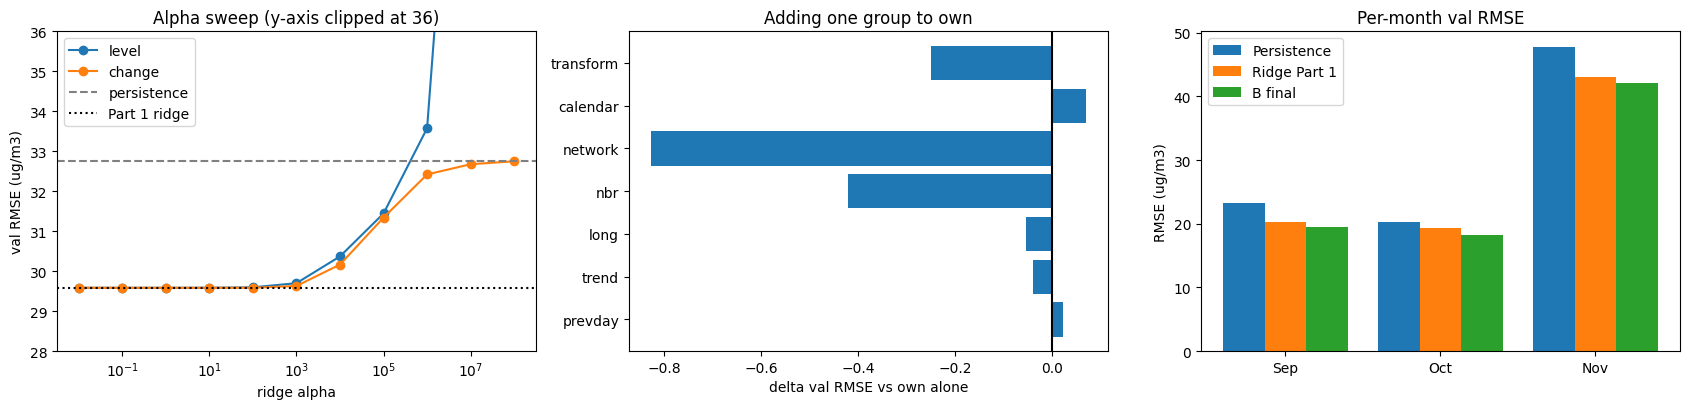

In [12]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

# (a) alpha curve, level vs change (29 Part 1 features, from Cell 4)
for tgt in ["level", "change"]:
    d = cmp_t[cmp_t.Target == tgt]; ax[0].plot(d.alpha, d.Val_RMSE, "o-", label=tgt)
ax[0].axhline(32.75, ls="--", c="gray", label="persistence"); ax[0].axhline(29.58, ls=":", c="k", label="Part 1 ridge")
ax[0].set_xscale("log"); ax[0].set_ylim(28, 36); ax[0].set_xlabel("ridge alpha"); ax[0].set_ylabel("val RMSE (ug/m3)")
ax[0].set_title("Alpha sweep (y-axis clipped at 36)"); ax[0].legend()

# (b) group-add: change in val RMSE vs own-only (Cell 7 table)
t = tab.iloc[1:-1]; ax[1].barh([g.replace("own+", "") for g in t.groups], t.d_val_rmse)
ax[1].axvline(0, c="k"); ax[1].set_xlabel("delta val RMSE vs own alone"); ax[1].set_title("Adding one group to own")

# (c) per-month RMSE
ev = {"Persistence": B.evaluate(B.persistence(W, T_va), y_va, T_va), "Ridge Part 1": B.evaluate(p1, y_va, T_va),
      "B final": B.evaluate(pv_full, y_va, T_va)}
x = np.arange(3)
for k, (n, e) in enumerate(ev.items()):
    ax[2].bar(x + 0.27 * k, [e["RMSE Sep"], e["RMSE Oct"], e["RMSE Nov"]], 0.27, label=n)
ax[2].set_xticks(x + 0.27); ax[2].set_xticklabels(["Sep", "Oct", "Nov"]); ax[2].set_ylabel("RMSE (ug/m3)")
ax[2].set_title("Per-month val RMSE"); ax[2].legend()
plt.tight_layout(); plt.savefig("fig_B_summary.png", dpi=150); plt.show()

### new experiments

In [13]:
Xa = np.hstack([blk_tr_f[g][0] for g in SEL]); Xb = np.hstack([blk_va[g][0] for g in SEL])
nm = [n for g in SEL for n in blk_tr_f[g][1]]
sc = StandardScaler().fit(Xa); Za, Zb = sc.transform(Xa), sc.transform(Xb)   # train only
rows = []
for tgt in ["level", "change"]:
    otr, ova = (X_tr[:, 0], X_va[:, 0]) if tgt == "change" else (0, 0)
    for a in [1e-3, 1e-2, 0.1, 0.3, 1, 3]:
        ls = Lasso(alpha=a, max_iter=50000, random_state=0).fit(Za, y_tr - otr)
        pt, pv = ls.predict(Za) + otr, ls.predict(Zb) + ova
        e = B.evaluate(pv, y_va, T_va); nz = ls.coef_ != 0
        rows.append(dict(target=tgt, alpha=a, nnz=int(nz.sum()), train=rmse(pt, y_tr), val=e["RMSE"], mae=e["MAE"],
                         sep=e["RMSE Sep"], oct=e["RMSE Oct"], nov=e["RMSE Nov"],
                         bias=np.mean(np.clip(pv, 0, None) - y_va),
                         **{g: int(sum(nz[i] for i, n in enumerate(nm) if n in blk_tr_f[g][1])) for g in SEL}))
print(pd.DataFrame(rows).round(2).to_string(index=False))

target  alpha  nnz  train   val   mae   sep   oct   nov  bias  own  network  trend  nbr
 level   0.00   33  27.87 28.71 16.43 19.51 18.15 42.17 -0.52   24        3      1    5
 level   0.01   33  27.87 28.70 16.43 19.51 18.15 42.17 -0.49   24        3      1    5
 level   0.10   23  27.90 28.72 16.47 19.55 18.15 42.18 -0.16   17        3      1    2
 level   0.30   20  28.00 28.83 16.63 19.63 18.29 42.30  0.41   16        2      1    1
 level   1.00   17  28.18 29.02 16.81 19.70 18.44 42.61  0.51   14        2      1    0
 level   3.00   15  28.51 29.32 17.09 19.83 18.48 43.14  0.15   14        1      0    0
change   0.00   33  27.87 28.71 16.43 19.51 18.15 42.17 -0.52   24        3      1    5
change   0.01   33  27.87 28.70 16.43 19.51 18.15 42.16 -0.49   24        3      1    5
change   0.10   23  27.91 28.67 16.44 19.53 18.11 42.12 -0.19   17        3      1    2
change   0.30   20  28.09 28.75 16.55 19.65 18.19 42.18  0.31   15        2      1    2
change   1.00   16  28.81 29.17 

In [14]:
Xa = np.hstack([blk_tr_f[g][0] for g in SEL]); Xb = np.hstack([blk_va[g][0] for g in SEL])
iss_month = T_tr.repeat(468).month.to_numpy()
rows = []
for k in [1, 2, 3, 5, 10]:
    w = np.where(iss_month <= 2, float(k), 1.0)
    m = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(Xa, y_tr, ridge__sample_weight=w)
    pt, pv = m.predict(Xa), m.predict(Xb); e = B.evaluate(pv, y_va, T_va)
    rows.append(dict(jan_feb_weight=k, train=rmse(pt, y_tr), val=e["RMSE"], mae=e["MAE"], sep=e["RMSE Sep"],
                     oct=e["RMSE Oct"], nov=e["RMSE Nov"], bias=np.mean(np.clip(pv, 0, None) - y_va)))
print(pd.DataFrame(rows).round(2).to_string(index=False))

 jan_feb_weight  train   val   mae   sep   oct   nov  bias
              1  27.87 28.71 16.43 19.51 18.16 42.17 -0.48
              2  27.89 28.73 16.51 19.51 18.34 42.14 -0.15
              3  27.91 28.75 16.55 19.51 18.45 42.13  0.05
              5  27.94 28.77 16.62 19.51 18.58 42.12  0.36
             10  27.99 28.81 16.72 19.51 18.75 42.11  0.90


Nov: top 5 days carry 41% of squared error, top 10 carry 61% (30 days)
lag0_bin     n  rmse_final  bias_final  rmse_persist
    0-25 18092        16.1        -0.5          17.0
   25-50 10008        20.2         0.9          20.8
  50-100  7730        29.6         0.1          31.5
 100-200  5596        45.5        -4.2          49.7
 200-501  1162        82.6         2.1         112.3


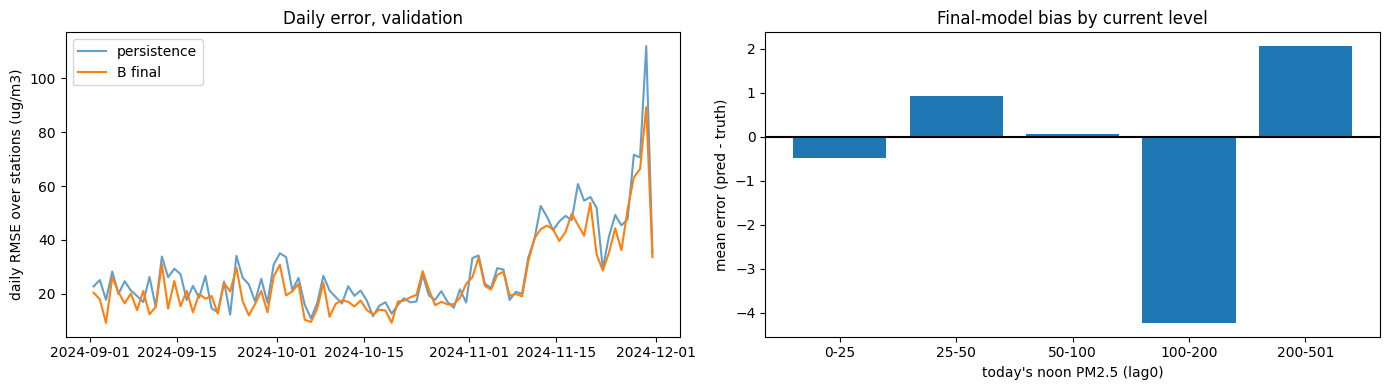

In [15]:
dates = T_va + pd.Timedelta(hours=24)
pp = B.persistence(W, T_va); pf = np.clip(pv_full, 0, None)
se_f = ((pf - y_va) ** 2).reshape(91, 468).mean(1); se_p = ((pp - y_va) ** 2).reshape(91, 468).mean(1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(dates, np.sqrt(se_p), label="persistence", alpha=.7); ax[0].plot(dates, np.sqrt(se_f), label="B final")
ax[0].set_ylabel("daily RMSE over stations (ug/m3)"); ax[0].set_title("Daily error, validation"); ax[0].legend()

nov = dates.month == 11
s = np.sort(se_f[nov])[::-1]
print(f"Nov: top 5 days carry {s[:5].sum()/s.sum():.0%} of squared error, top 10 carry {s[:10].sum()/s.sum():.0%} (30 days)")

# error by today's level (lag0), final vs persistence
lag0 = X_va[:, 0]; bins = [0, 25, 50, 100, 200, 501]; b = np.digitize(lag0, bins) - 1
out = []
for i in range(len(bins) - 1):
    mk = b == i
    out.append(dict(lag0_bin=f"{bins[i]}-{bins[i+1]}", n=int(mk.sum()),
                    rmse_final=np.sqrt(np.mean((pf[mk] - y_va[mk]) ** 2)), bias_final=np.mean(pf[mk] - y_va[mk]),
                    rmse_persist=np.sqrt(np.mean((pp[mk] - y_va[mk]) ** 2))))
print(pd.DataFrame(out).round(1).to_string(index=False))
ax[1].bar([o["lag0_bin"] for o in out], [o["bias_final"] for o in out]); ax[1].axhline(0, c="k")
ax[1].set_xlabel("today's noon PM2.5 (lag0)"); ax[1].set_ylabel("mean error (pred - truth)")
ax[1].set_title("Final-model bias by current level"); plt.tight_layout(); plt.savefig("fig_B_errors.png", dpi=150); plt.show()

In [16]:
tgt_d = (T_trm + pd.Timedelta(hours=24)).repeat(468)
sets = {"own": ["own"], "own+network": ["own", "network"], "SEL (own+network+trend+nbr)": SEL,
        "all minus long": [g for g in ALL if g != "long"]}
folds = {"train<=Apr, test May-Jun": ("2024-04-30 23:59", "2024-05-01", "2024-06-30 23:59"),
         "train<=Jun, test Jul-Aug": ("2024-06-30 23:59", "2024-07-01", "2024-08-31 23:59")}
rows = []
for fn, (tr_end, te0, te1) in folds.items():
    tr = tgt_d <= pd.Timestamp(tr_end); te = (tgt_d >= pd.Timestamp(te0)) & (tgt_d <= pd.Timestamp(te1))
    lag0_te = blk_tr["own"][0][te, 0]
    rows.append(dict(fold=fn, model="persistence", rmse=np.sqrt(np.mean((lag0_te - y_trm[te]) ** 2)),
                     mae=np.mean(np.abs(lag0_te - y_trm[te]))))
    for sn, gs in sets.items():
        Xf = np.hstack([blk_tr[g][0] for g in gs])
        m = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(Xf[tr], y_trm[tr])
        p = np.clip(m.predict(Xf[te]), 0, None)
        rows.append(dict(fold=fn, model=sn, rmse=np.sqrt(np.mean((p - y_trm[te]) ** 2)), mae=np.mean(np.abs(p - y_trm[te]))))
print(pd.DataFrame(rows).round(2).to_string(index=False))

                    fold                       model  rmse  mae
train<=Apr, test May-Jun                 persistence 19.61 9.19
train<=Apr, test May-Jun                         own 16.08 8.24
train<=Apr, test May-Jun                 own+network 16.11 8.23
train<=Apr, test May-Jun SEL (own+network+trend+nbr) 16.10 8.30
train<=Apr, test May-Jun              all minus long 16.46 8.61
train<=Jun, test Jul-Aug                 persistence 21.25 8.88
train<=Jun, test Jul-Aug                         own 17.38 7.94
train<=Jun, test Jul-Aug                 own+network 17.40 7.92
train<=Jun, test Jul-Aug SEL (own+network+trend+nbr) 17.25 7.84
train<=Jun, test Jul-Aug              all minus long 17.26 8.36


In [17]:
from features_B import _i, _cs, _wmean
A75 = B.neighbour_matrix(stations, k=75)
def alt(W, T, ctx):
    cs, i = _cs(W), _i(W, T); Wv = W.to_numpy(); m18 = _wmean(cs, i, 18)
    cols = [Wv[i] - Wv[i - 18], Wv[i] - m18, Wv[i] @ A75.T, m18 @ A75.T]
    return np.stack(cols, axis=2).reshape(-1, 4), ["diff18", "dev18", "nbr75_now", "nbr75_mean18"]

for T_, j in [(T_tr, 0), (T_tr, 100), (T_va, 10)]:                       # leakage + parity
    t = T_[j]; a = alt(W, [t], ctx)[0]
    assert np.allclose(a, alt(W.loc[:t], [t], ctx)[0]), "LEAK alt"
    blk = alt(W, T_, ctx)[0]; assert np.allclose(a, blk[j * 468:(j + 1) * 468]), "PARITY alt"
blk_tr_f["alt"], blk_va["alt"] = alt(W, T_tr, ctx), alt(W, T_va, ctx)
print("alt OK")

rows = []
for name, gs in {"SEL (reference)": SEL, "SEL + alt": SEL + ["alt"],
                 "own+network+alt": ["own", "network", "alt"], "own+alt": ["own", "alt"]}.items():
    r, _, pv = fit_eval(gs, 100); rows.append(dict(model=name, **r))
    if name == "SEL + alt": pv_alt = pv
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("delta RMSE (SEL+alt minus SEL), 95% block CI:", block_boot(day_se(pv_alt), day_se(pv_full)))

alt OK
          model  n_feat  train   val   mae   sep   oct   nov  bias
SEL (reference)      33  27.87 28.71 16.43 19.51 18.16 42.17 -0.48
      SEL + alt      37  27.86 28.69 16.40 19.50 18.11 42.16 -0.58
own+network+alt      31  27.99 28.82 16.43 19.59 18.11 42.40 -0.58
        own+alt      28  28.42 29.34 16.87 19.71 18.48 43.24  0.01
delta RMSE (SEL+alt minus SEL), 95% block CI: [-0.04 -0.01  0.02]


Net result: none of the new experiments beats the current final model (28.71 / 16.43). That’s a useful negative result, and it makes the final choice easier to defend.